In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from openbb import obb
from scipy.stats import spearmanr

In [2]:
obb.user.preferences.output_type = "dataframe"

In [3]:
symbols = ["RELIANCE.NS", "HINDALCO.NS" , "SBIN.NS", "TCS.NS", "TRENT.NS", "EICHERMOT.NS", "DRREDDY.NS", "ITC.NS"]

data = obb.equity.price.historical(
    symbols,
    start_date="2017-01-01",
    end_date="2025-12-31",
    provider="yfinance",
)

In [4]:
prices = data[["high", "low", "close", "volume", "symbol"]]

In [5]:
nobs = prices.groupby("symbol").size()
mask = nobs[nobs > 2 * 12 * 21].index
prices = prices[prices.symbol.isin(mask)]

In [6]:
prices = (
    prices.set_index("symbol", append=True)
    .reorder_levels(["symbol", "date"])
    .sort_index(level=0)
).drop_duplicates()

In [7]:
prices

high          low        close     volume
symbol     date                                                        
DRREDDY.NS 2017-01-02   623.400024   613.200012   616.679993   477630.0
           2017-01-03   622.989990   613.150024   614.479980   554600.0
           2017-01-04   622.659973   615.010010   618.260010  1179225.0
           2017-01-05   629.000000   615.200012   627.250000  1218265.0
           2017-01-06   640.770020   629.140015   631.830017  1770195.0
...                            ...          ...          ...        ...
TRENT.NS   2025-12-24  4313.299805  4183.100098  4289.600098   960632.0
           2025-12-26  4338.399902  4263.000000  4285.299805  1029780.0
           2025-12-29  4319.899902  4211.100098  4226.000000   423139.0
           2025-12-30  4257.700195  4187.799805  4207.700195   670540.0
           2025-12-31  4288.100098  4212.000000  4279.000000   426359.0

[17792 rows x 4 columns]

In [8]:
def parkinson(data, window=14, trading_days=252):
    rs = (1.0 / (4.0 * np.log(2.0))) * ((data.high / data.low).apply(np.log)) ** 2.0

    def f(v):
        return (trading_days * v.mean()) ** 0.5

    result = rs.rolling(window=window, center=False).apply(func=f)

    return result.sub(result.mean()).div(result.std())

In [9]:
prices["vol"] = prices.groupby("symbol", group_keys=False).apply(parkinson)
prices.dropna(inplace=True)

In [10]:
prices

high          low        close     volume  \
symbol     date                                                           
DRREDDY.NS 2017-01-19   594.950012   586.690002   588.049988  1407100.0   
           2017-01-20   591.940002   584.000000   589.479980  1204385.0   
           2017-01-23   591.989990   580.799988   584.729980  1196865.0   
           2017-01-24   595.960022   586.349976   594.669983   996480.0   
           2017-01-25   601.799988   591.130005   599.260010  1638155.0   
...                            ...          ...          ...        ...   
TRENT.NS   2025-12-24  4313.299805  4183.100098  4289.600098   960632.0   
           2025-12-26  4338.399902  4263.000000  4285.299805  1029780.0   
           2025-12-29  4319.899902  4211.100098  4226.000000   423139.0   
           2025-12-30  4257.700195  4187.799805  4207.700195   670540.0   
           2025-12-31  4288.100098  4212.000000  4279.000000   426359.0   

                            vol  
symbol     date                  
DRREDDY.NS 2017-01-19 -0.761340  
           2017-01-20 -0.778652  
           2017-01-23 -0.757335  
           2017-01-24 -0.736143  
           2017-01-25 -0.768978  
...                         ...  
TRENT.NS   2025-12-24 -0.950529  
           2025-12-26 -0.940323  
           2025-12-29 -0.969234  
           2025-12-30 -1.047112  
           2025-12-31 -1.118732  

[17688 rows x 5 columns]

In [11]:
lags = [1, 5, 10, 21, 42, 63]
for lag in lags:
    prices[f"return_{lag}d"] = prices.groupby(level="symbol").close.pct_change(lag)

In [12]:
for t in [1, 5, 10, 21, 42, 63]:
    prices[f"target_{t}d"] = prices.groupby(level="symbol")[f"return_{t}d"].shift(-t)

In [13]:
display(prices)

high          low        close     volume  \
symbol     date                                                           
DRREDDY.NS 2017-01-19   594.950012   586.690002   588.049988  1407100.0   
           2017-01-20   591.940002   584.000000   589.479980  1204385.0   
           2017-01-23   591.989990   580.799988   584.729980  1196865.0   
           2017-01-24   595.960022   586.349976   594.669983   996480.0   
           2017-01-25   601.799988   591.130005   599.260010  1638155.0   
...                            ...          ...          ...        ...   
TRENT.NS   2025-12-24  4313.299805  4183.100098  4289.600098   960632.0   
           2025-12-26  4338.399902  4263.000000  4285.299805  1029780.0   
           2025-12-29  4319.899902  4211.100098  4226.000000   423139.0   
           2025-12-30  4257.700195  4187.799805  4207.700195   670540.0   
           2025-12-31  4288.100098  4212.000000  4279.000000   426359.0   

                            vol  return_1d  return_5d  return_10d  return_21d  \
symbol     date                                                                 
DRREDDY.NS 2017-01-19 -0.761340        NaN        NaN         NaN         NaN   
           2017-01-20 -0.778652   0.002432        NaN         NaN         NaN   
           2017-01-23 -0.757335  -0.008058        NaN         NaN         NaN   
           2017-01-24 -0.736143   0.016999        NaN         NaN         NaN   
           2017-01-25 -0.768978   0.007719        NaN         NaN         NaN   
...                         ...        ...        ...         ...         ...   
TRENT.NS   2025-12-24 -0.950529   0.023918   0.060417    0.067516    0.010768   
           2025-12-26 -0.940323  -0.001002   0.063350    0.058752   -0.001654   
           2025-12-29 -0.969234  -0.013838   0.040323    0.036953   -0.009400   
           2025-12-30 -1.047112  -0.004330   0.000214    0.024020   -0.010046   
           2025-12-31 -1.118732   0.016945   0.021387    0.041449    0.014967   

                       return_42d  return_63d  target_1d  target_5d  \
symbol     date                                                       
DRREDDY.NS 2017-01-19         NaN         NaN   0.002432   0.018468   
           2017-01-20         NaN         NaN  -0.008058   0.023631   
           2017-01-23         NaN         NaN   0.016999   0.032545   
           2017-01-24         NaN         NaN   0.007719   0.009367   
           2017-01-25         NaN         NaN  -0.000584   0.033625   
...                           ...         ...        ...        ...   
TRENT.NS   2025-12-24   -0.104393   -0.122961  -0.001002        NaN   
           2025-12-26   -0.106987   -0.124913  -0.013838        NaN   
           2025-12-29   -0.105684   -0.108909  -0.004330        NaN   
           2025-12-30   -0.119838   -0.100727   0.016945        NaN   
           2025-12-31   -0.098114   -0.095444        NaN        NaN   

                       target_10d  target_21d  target_42d  target_63d  
symbol     date                                                        
DRREDDY.NS 2017-01-19    0.069484   -0.014114   -0.105110   -0.100094  
           2017-01-20    0.050689   -0.018101   -0.108248   -0.114253  
           2017-01-23    0.048381   -0.006995   -0.099772   -0.111881  
           2017-01-24    0.014159   -0.028907   -0.112869   -0.125851  
           2017-01-25    0.008944   -0.046491   -0.121033   -0.138054  
...                           ...         ...         ...         ...  
TRENT.NS   2025-12-24         NaN         NaN         NaN         NaN  
           2025-12-26         NaN         NaN         NaN         NaN  
           2025-12-29         NaN         NaN         NaN         NaN  
           2025-12-30         NaN         NaN         NaN         NaN  
           2025-12-31         NaN         NaN         NaN         NaN  

[17688 rows x 17 columns]

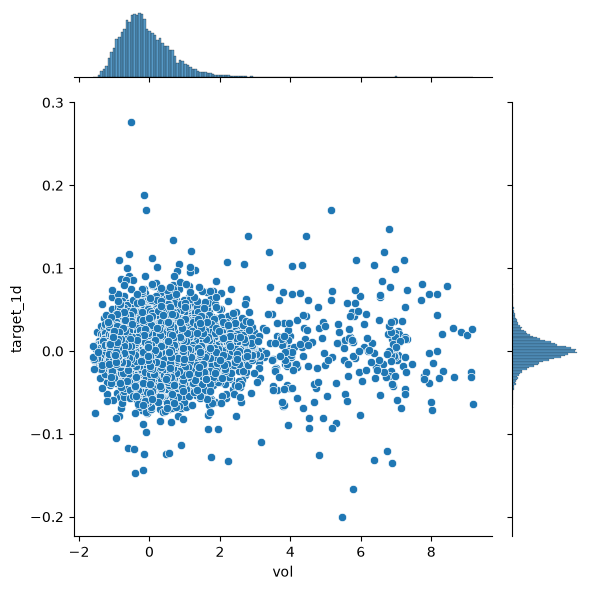

In [14]:
target = "target_1d"
metric = "vol"
j = sns.jointplot(x=metric, y=target, data=prices)
plt.tight_layout()

In [15]:
df = prices[[metric, target]].dropna()
r, p = spearmanr(df[metric], df[target])
display(f"{r:,.2%} ({p:.2%})")

'-0.16% (82.90%)'

In [16]:
d = prices.loc["ITC.NS"].head(10)
display(d)

,high,low,close,volume,vol,return_1d,return_5d,return_10d,return_21d,return_42d,return_63d,target_1d,target_5d,target_10d,target_21d,target_42d,target_63d
date,,,,,,,,,,,,,,,,,
2017-01-19,245.302658,240.295502,244.724915,9538148.0,-0.082316,NaN,NaN,NaN,NaN,NaN,NaN,0.004918,0.012788,0.074366,0.046823,0.092268,0.106827
2017-01-20,246.795181,244.291595,245.928558,11261533.0,-0.106642,0.004918,NaN,NaN,NaN,NaN,NaN,0.016641,0.002741,0.083790,0.030345,0.100235,0.138998
2017-01-23,250.502396,245.591537,250.020950,11101905.0,-0.168474,0.016641,NaN,NaN,NaN,NaN,NaN,0.000770,-0.005970,0.067206,0.014635,0.084537,0.100712
2017-01-24,251.080154,247.806244,250.213531,8341113.0,-0.297290,0.000770,NaN,NaN,NaN,NaN,NaN,0.021743,0.037906,0.057533,0.022321,0.079469,0.069848
2017-01-25,256.520630,249.972794,255.653992,18123606.0,-0.207386,0.021743,NaN,NaN,NaN,NaN,NaN,-0.030508,0.033145,0.045763,-0.003390,0.066667,0.051601
2017-01-27,257.050232,246.602600,247.854385,25440485.0,-0.022166,-0.030508,0.012788,NaN,NaN,NaN,NaN,-0.005050,0.060800,0.061966,0.018648,0.098485,0.077117
2017-01-30,251.320877,246.024841,246.602600,9253765.0,-0.000915,-0.005050,0.002741,NaN,NaN,NaN,NaN,0.007809,0.080828,0.056618,0.048419,0.094494,0.098009
2017-01-31,250.309814,245.158218,248.528427,10380649.0,0.027013,0.007809,-0.005970,NaN,NaN,NaN,NaN,0.044944,0.073615,0.049206,0.025765,0.090856,0.073809
2017-02-01,260.083405,248.913589,259.698242,35144107.0,0.317196,0.044944,0.037906,NaN,NaN,NaN,NaN,0.017056,0.018910,0.013719,-0.030219,0.034297,0.012050


In [17]:
display(df[metric])
display(df[target])

symbol      date      
DRREDDY.NS  2017-01-19   -0.761340
            2017-01-20   -0.778652
            2017-01-23   -0.757335
            2017-01-24   -0.736143
            2017-01-25   -0.768978
                            ...   
TRENT.NS    2025-12-23   -1.014542
            2025-12-24   -0.950529
            2025-12-26   -0.940323
            2025-12-29   -0.969234
            2025-12-30   -1.047112
Name: vol, Length: 17680, dtype: float64

symbol      date      
DRREDDY.NS  2017-01-19    0.002432
            2017-01-20   -0.008058
            2017-01-23    0.016999
            2017-01-24    0.007719
            2017-01-25   -0.000584
                            ...   
TRENT.NS    2025-12-23    0.023918
            2025-12-24   -0.001002
            2025-12-26   -0.013838
            2025-12-29   -0.004330
            2025-12-30    0.016945
Name: target_1d, Length: 17680, dtype: float64

In [18]:
display(r, p)

np.float64(-0.0016247764857738472)

np.float64(0.828968135955826)

## Hypothesis test
- H0: no monotonic relationship between Parkinson volatility and next-day return (rho = 0).
- Reject H0 only if **p < 0.05**. A large p-value means *no evidence* of a relationship.

In [19]:
ALPHA = 0.05
verdict = "REJECT H0" if p < ALPHA else "FAIL TO REJECT H0"
print(f"Signed next-day return:  rho={r:+.4f}, p={p:.4f} -> {verdict}")

Signed next-day return:  rho=-0.0016, p=0.8290 -> FAIL TO REJECT H0


## Follow-up: volatility predicts the *size* of moves, not their direction
Same test with absolute next-day return as the target (volatility clustering).

In [20]:
prices["abs_target_1d"] = prices["target_1d"].abs()
df_abs = prices[[metric, "abs_target_1d"]].dropna()
r_abs, p_abs = spearmanr(df_abs[metric], df_abs["abs_target_1d"])
verdict_abs = "REJECT H0" if p_abs < ALPHA else "FAIL TO REJECT H0"
print(f"Absolute next-day return: rho={r_abs:+.4f}, p={p_abs:.3g} -> {verdict_abs}")

Absolute next-day return: rho=+0.1816, p=6.22e-131 -> REJECT H0
